In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, poisson
import time
import pandas as pd

np.random.seed(0)

# paramètres de l'option
S0 = 100
K = 100
T = 5
r = 0.03

# paramètre de la diffusion (partie Black-Scholes)
sigma = 0.2

# paramètres des sauts
lam = 0.75      # nombre moyen de sauts par an
muJ = -0.10     # taille moyenne d'un saut (en log)
delta = 0.15    # dispersion des sauts

kappa = np.exp(muJ + 0.5*delta**2) - 1
print("kappa = ", kappa, " soit un saut moyen de", 100*kappa, "%")

kappa =  -0.08492568644084764  soit un saut moyen de -8.492568644084763 %


In [16]:
def bs_call(S, K, T, r, sig):
    # prix d'un call européen dans Black-Scholes
    d1 = (np.log(S/K) + (r + 0.5*sig**2)*T) / (sig*np.sqrt(T))
    d2 = d1 - sig*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)


def merton_call(S, K, T, r, sig, lam, muJ, delta):
    # prix de Merton = moyenne des prix Black-Scholes pondérée par la probabilité d'avoir n sauts
    kap = np.exp(muJ + 0.5*delta**2) - 1
    lam2 = lam*(1 + kap)                            # intensité ajustée
    prix = 0
    for n in range(60):
        proba = poisson.pmf(n, lam2*T)              # probabilité d'avoir n sauts
        sig_n = np.sqrt(sig**2 + n*delta**2/T)      # volatilité avec n sauts
        r_n = r - lam*kap + n*np.log(1 + kap)/T     # taux ajusté avec n sauts
        prix = prix + proba*bs_call(S, K, T, r_n, sig_n)
    return prix


C_ref = merton_call(S0, K, T, r, sigma, lam, muJ, delta)
print("Call Merton : ", C_ref)
print("Call Black-Scholes (sigma =", sigma, ") : ", bs_call(S0, K, T, r, sigma))

# vérification : sans sauts (lambda = 0), on doit retrouver Black-Scholes
print("Call Merton sans sauts : ", merton_call(S0, K, T, r, sigma, 0, muJ, delta))
sig=0.254
print("Call Black-Scholes (sigma =", sig, ") : ", bs_call(S0, K, T, r, sig))


Call Merton :  28.10543943289801
Call Black-Scholes (sigma = 0.2 ) :  24.326053427063215
Call Merton sans sauts :  24.326053427063215
Call Black-Scholes (sigma = 0.254 ) :  28.465376184904976


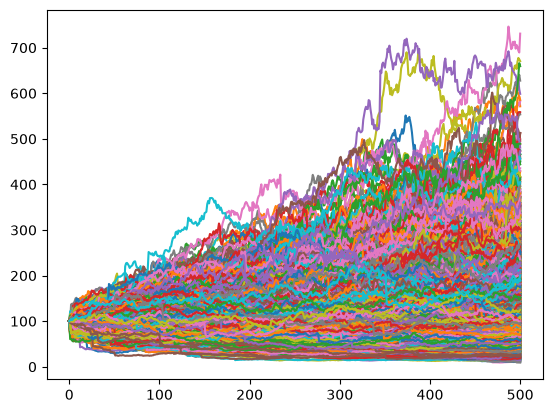

In [17]:
# Trajectoires de Monte-Carlo : Black-Scholes et Merton
kappa = np.exp(muJ + 0.5*delta**2) - 1

n = 500          # nombre de pas de temps
dt = T/n
Ntraj = 10000      # nombre de trajectoires à afficher

S = np.zeros((n+1, Ntraj))      # trajectoires Merton
S[0, :] = S0


for i in range(n):
    Z = np.random.normal(size=Ntraj)                      # même aléa brownien pour les deux modèles
    Nsauts = np.random.poisson(lam*dt, size=Ntraj)        # 0 ou 1 saut (rarement plus) pendant dt
    sauts = muJ*Nsauts + delta*np.sqrt(Nsauts)*np.random.normal(size=Ntraj)
    S[i+1, :] = S[i, :]*(1 + (r - lam*kappa)*dt + sigma*np.sqrt(dt)*Z + (np.exp(sauts) - 1))


plt.plot(S)
plt.show()

In [18]:
# valeur finale theorque
ST = S0*np.exp(r*T)
print("Prix théorique  : ", ST)

#valeur finale simulée
ST_sim = S0*(1+r*dt)**n
print("Prix numérique : ", ST_sim)

#valeur finale estimée(empirique)
ST_Empirique = np.mean(S[-1,:])
print("Prix empirique Merton : ", ST_Empirique)

Prix théorique  :  116.1834242728283
Prix numérique :  116.180810697885
Prix empirique Merton :  115.02284998733431


In [19]:
# prix du call à partir de la dernière valeur de chaque trajectoire
CT = np.maximum(S[-1, :] - K, 0)
C0 = np.exp(-r*T)*np.mean(CT)   


print("Prix (trajectoires pas à pas) : ", C0)
print("Prix formule                  : ", C_ref)


Prix (trajectoires pas à pas) :  27.248877275979538
Prix formule                  :  28.10543943289801


In [20]:
kappa = np.exp(muJ + 0.5*delta**2) - 1

Z = np.random.normal(size=Ntraj)
Nsauts = np.random.poisson(lam*T, size=Ntraj)
sauts = muJ*Nsauts + delta*np.sqrt(Nsauts)*np.random.normal(size=Ntraj)
ST = S0*np.exp((r - lam*kappa - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z + sauts)
CT = np.maximum(ST - K, 0)
C0 = np.exp(-r*T)*np.mean(CT)

print("Prix (simulation directe) : ", C0)
print("Prix formule              : ", C_ref)


Prix (simulation directe) :  28.014141589401994
Prix formule              :  28.10543943289801


In [21]:
# intervalle de confiance à 99 %
z = norm.ppf(0.995)

# IC sur E[S_T] (vérification : doit contenir S0*exp(rT))
sigmachapeau = np.std(ST, ddof=1)
Smin = np.mean(ST) - z*sigmachapeau/np.sqrt(Ntraj)
Smax = np.mean(ST) + z*sigmachapeau/np.sqrt(Ntraj)
print("IC 99% de E[S_T] : [", Smin, ",", Smax, "]   théorie :", S0*np.exp(r*T))

# IC sur le prix du call
sigmachapeau = np.std(np.exp(-r*T)*CT, ddof=1)
Cmin = C0 - z*sigmachapeau/np.sqrt(Ntraj)
Cmax = C0 + z*sigmachapeau/np.sqrt(Ntraj)
print("IC 99% du call   : [", Cmin, ",", Cmax, "]   formule :", C_ref)

IC 99% de E[S_T] : [ 114.02863579903465 , 117.59958306859605 ]   théorie : 116.1834242728283
IC 99% du call   : [ 26.753541886814457 , 29.274741291989532 ]   formule : 28.10543943289801


N = 1000   erreur moyenne = 1.3465069265109388
N = 4000   erreur moyenne = 0.806488270885187
N = 16000   erreur moyenne = 0.39932518971744585
N = 64000   erreur moyenne = 0.23957767880469227
N = 256000   erreur moyenne = 0.0898324960750022
Pente observée : -0.47814204458375165 (théorie : -0.5)


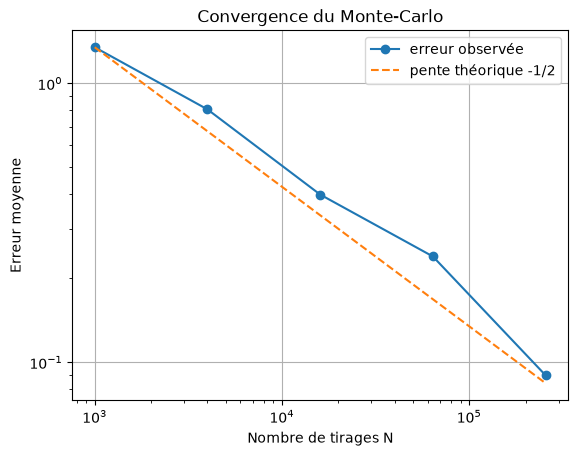

In [22]:
# Convergence du Monte-Carlo (simulation directe)
kappa = np.exp(muJ + 0.5*delta**2) - 1
liste_N = [1000, 4000, 16000, 64000, 256000]
nb_rep = 30      # nombre de répétitions pour chaque N
rmse = []

for N in liste_N:
    erreurs = []
    for k in range(nb_rep):
        Z = np.random.normal(size=N)
        Nsauts = np.random.poisson(lam*T, size=N)
        sauts = muJ*Nsauts + delta*np.sqrt(Nsauts)*np.random.normal(size=N)
        ST = S0*np.exp((r - lam*kappa - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z + sauts)
        C0 = np.exp(-r*T)*np.mean(np.maximum(ST - K, 0))
        erreurs.append((C0 - C_ref)**2)
    rmse.append(np.sqrt(np.mean(erreurs)))
    print("N =", N, "  erreur moyenne =", rmse[-1])

# pente de la droite en échelle log-log
pente = np.polyfit(np.log(liste_N), np.log(rmse), 1)[0]
print("Pente observée :", pente, "(théorie : -0.5)")

plt.loglog(liste_N, rmse, 'o-', label="erreur observée")
plt.loglog(liste_N, rmse[0]*np.sqrt(liste_N[0]/np.array(liste_N)), '--', label="pente théorique -1/2")
plt.xlabel("Nombre de tirages N")
plt.ylabel("Erreur moyenne")
plt.title("Convergence du Monte-Carlo")
plt.legend()
plt.grid()
plt.show()

In [23]:
# Réduction de variance : antithétique et variable de contrôle
kappa = np.exp(muJ + 0.5*delta**2) - 1
z = norm.ppf(0.995)

Z = np.random.normal(size=Ntraj)
G = np.random.normal(size=Ntraj)
Nsauts = np.random.poisson(lam*T, size=Ntraj)
d = (r - lam*kappa - 0.5*sigma**2)*T

# 1) Monte-Carlo simple
ST = S0*np.exp(d + sigma*np.sqrt(T)*Z + muJ*Nsauts + delta*np.sqrt(Nsauts)*G)
CT = np.exp(-r*T)*np.maximum(ST - K, 0)
C0 = np.mean(CT)
sigmachapeau = np.std(CT, ddof=1)

# 2) Variables antithétiques : on rejoue avec -Z et -G
ST_anti = S0*np.exp(d - sigma*np.sqrt(T)*Z + muJ*Nsauts - delta*np.sqrt(Nsauts)*G)
CT_anti = np.exp(-r*T)*np.maximum(ST_anti - K, 0)
CT_A = 0.5*(CT + CT_anti)
C0_A = np.mean(CT_A)
sigmachapeau_A = np.std(CT_A, ddof=1)

# 3) Variable de contrôle : X = exp(-rT) S_T, d'espérance connue S0
X = np.exp(-r*T)*ST
b = np.cov(CT, X)[0, 1]/np.var(X, ddof=1)
CT_C = CT - b*(X - S0)
C0_C = np.mean(CT_C)
sigmachapeau_C = np.std(CT_C, ddof=1)

print("Prix exact            :", C_ref)
print("MC simple             :", C0, " ±", z*sigmachapeau/np.sqrt(Ntraj))
print("Antithétique          :", C0_A, " ±", z*sigmachapeau_A/np.sqrt(Ntraj))
print("Variable de contrôle  :", C0_C, " ±", z*sigmachapeau_C/np.sqrt(Ntraj))
print("Corrélation call / S_T :", np.corrcoef(CT, X)[0, 1], "   b =", b)
print("Gain antithétique     :", sigmachapeau**2/(2*sigmachapeau_A**2))
print("Gain contrôle         :", sigmachapeau**2/sigmachapeau_C**2)

Prix exact            : 28.10543943289801
MC simple             : 28.245305162772404  ± 1.228947730906297
Antithétique          : 28.14666325618105  ± 0.7147309807336403
Variable de contrôle  : 28.12152392391888  ± 0.35516048688353663
Corrélation call / S_T : 0.9573304252819226    b = 0.7795289872638976
Gain antithétique     : 1.4782626821837621
Gain contrôle         : 11.973401305067881


In [24]:
# Méthode COS (Fang-Oosterlee) pour le call Merton
def cos_call(S, K, T, r, sig, lam, muJ, delta, Ncos):
    kap = np.exp(muJ + 0.5*delta**2) - 1
    # intervalle [a, b] : moyenne de X ± 10 écarts-types
    c1 = (r - lam*kap - 0.5*sig**2)*T + lam*T*muJ
    c2 = sig**2*T + lam*T*(muJ**2 + delta**2)
    x = np.log(S/K)
    a = x + c1 - 10*np.sqrt(c2)
    b = x + c1 + 10*np.sqrt(c2)
    k = np.arange(Ncos)
    u = k*np.pi/(b - a)
    # fonction caractéristique de Merton
    phi = np.exp(1j*u*(r - lam*kap - 0.5*sig**2)*T - 0.5*sig**2*u**2*T
                 + lam*T*(np.exp(1j*u*muJ - 0.5*delta**2*u**2) - 1))
    # coefficients cosinus du payoff du call
    chi = (np.cos(u*(b - a))*np.exp(b) - np.cos(-u*a)
           + u*np.sin(u*(b - a))*np.exp(b) - u*np.sin(-u*a)) / (1 + u**2)
    psi = np.zeros(Ncos)
    psi[0] = b
    psi[1:] = (np.sin(u[1:]*(b - a)) - np.sin(-u[1:]*a)) / u[1:]
    Vk = 2/(b - a)*K*(chi - psi)
    # somme des termes (le premier compte pour moitié)
    terme = np.real(phi*np.exp(1j*u*(x - a)))*Vk
    terme[0] = 0.5*terme[0]
    return np.exp(-r*T)*np.sum(terme)


C_cos = cos_call(S0, K, T, r, sigma, lam, muJ, delta, 64)
print("Prix COS (64 termes) :", C_cos)
print("Prix formule fermée  :", C_ref)
print("Erreur               :", abs(C_cos - C_ref))

# temps de calcul
t0 = time.time()
for i in range(1000):
    C_cos = cos_call(S0, K, T, r, sigma, lam, muJ, delta, 64)
t_cos = (time.time() - t0)/1000

t0 = time.time()
for i in range(100):
    C_f = merton_call(S0, K, T, r, sigma, lam, muJ, delta)
t_formule = (time.time() - t0)/100

Nmc = 100000
kappa = np.exp(muJ + 0.5*delta**2) - 1
t0 = time.time()
Z = np.random.normal(size=Nmc)
Nsauts = np.random.poisson(lam*T, size=Nmc)
G = np.random.normal(size=Nmc)
ST = S0*np.exp((r - lam*kappa - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z + muJ*Nsauts + delta*np.sqrt(Nsauts)*G)
CT = np.exp(-r*T)*np.maximum(ST - K, 0)
C_mc = np.mean(CT)
t_mc = time.time() - t0

print("\nTemps COS            :", t_cos, "s")
print("Temps formule fermée :", t_formule, "s")
print("Temps MC (N=100000)  :", t_mc, "s   prix =", C_mc, "±", norm.ppf(0.995)*np.std(CT, ddof=1)/np.sqrt(Nmc))
print("MC / COS             :", t_mc/t_cos)

Prix COS (64 termes) : 28.105439432901342
Prix formule fermée  : 28.10543943289801
Erreur               : 3.33244543071487e-12

Temps COS            : 0.00010147690773010254 s
Temps formule fermée : 0.010707783699035644 s
Temps MC (N=100000)  : 0.012866020202636719 s   prix = 28.577832945338994 ± 0.3977886329589355
MC / COS             : 126.78766519823789


T = 0.25  erreurs COS : [np.float64(0.3040681198545414), np.float64(0.02701432501915324), np.float64(0.0014748673931812561), np.float64(3.182101968057793e-05), np.float64(1.4669527814703542e-09), np.float64(6.896403448308774e-10), np.float64(6.896403448308774e-10), np.float64(6.896403448308774e-10)]
T = 5  erreurs COS : [np.float64(242.11408573205404), np.float64(9.084748687835663), np.float64(0.13057406506236546), np.float64(4.3405685346442624e-05), np.float64(8.40659453160697e-09), np.float64(3.33244543071487e-12), np.float64(3.33244543071487e-12), np.float64(3.33244543071487e-12)]


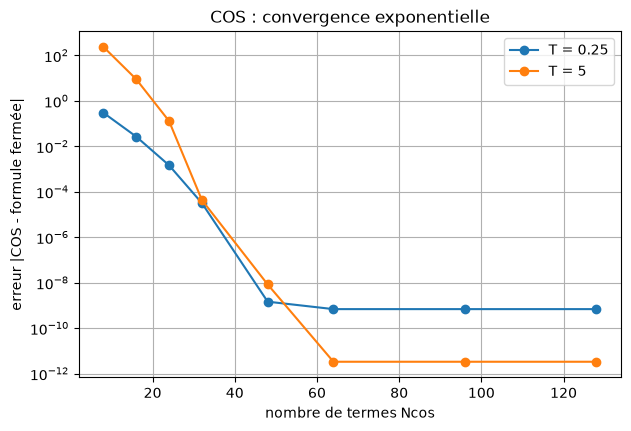

In [25]:
liste_Ncos = [8, 16, 24, 32, 48, 64, 96, 128]
plt.figure(figsize=(7, 4.5))
for Tm in [0.25, 5]:
    C_exact = merton_call(S0, K, Tm, r, sigma, lam, muJ, delta)
    erreurs = []
    for Ncos in liste_Ncos:
        erreurs.append(abs(cos_call(S0, K, Tm, r, sigma, lam, muJ, delta, Ncos) - C_exact))
    print("T =", Tm, " erreurs COS :", erreurs)
    plt.semilogy(liste_Ncos, erreurs, 'o-', label="T = " + str(Tm))
plt.xlabel("nombre de termes Ncos")
plt.ylabel("erreur |COS - formule fermée|")
plt.title("COS : convergence exponentielle")
plt.legend()
plt.grid()

plt.show()

In [26]:
# Comparaison finale des méthodes (T = 5, K = 100), 100 000 payoffs pour chaque MC
z = norm.ppf(0.995)
Nmc = 100000
kappa = np.exp(muJ + 0.5*delta**2) - 1
d = (r - lam*kappa - 0.5*sigma**2)*T

# MC simple
t0 = time.time()
Z = np.random.normal(size=Nmc); G = np.random.normal(size=Nmc); Nsauts = np.random.poisson(lam*T, size=Nmc)
ST = S0*np.exp(d + sigma*np.sqrt(T)*Z + muJ*Nsauts + delta*np.sqrt(Nsauts)*G)
CT = np.exp(-r*T)*np.maximum(ST - K, 0)
C_simple = np.mean(CT); ic_simple = z*np.std(CT, ddof=1)/np.sqrt(Nmc)
t_simple = time.time() - t0

# Antithétique (Nmc/2 paires = même nombre de payoffs)
t0 = time.time()
M = Nmc//2
Z = np.random.normal(size=M); G = np.random.normal(size=M); Nsauts = np.random.poisson(lam*T, size=M)
ST1 = S0*np.exp(d + sigma*np.sqrt(T)*Z + muJ*Nsauts + delta*np.sqrt(Nsauts)*G)
ST2 = S0*np.exp(d - sigma*np.sqrt(T)*Z + muJ*Nsauts - delta*np.sqrt(Nsauts)*G)
CT_A = 0.5*np.exp(-r*T)*(np.maximum(ST1 - K, 0) + np.maximum(ST2 - K, 0))
C_anti = np.mean(CT_A); ic_anti = z*np.std(CT_A, ddof=1)/np.sqrt(M)
t_anti = time.time() - t0

# Variable de contrôle
t0 = time.time()
Z = np.random.normal(size=Nmc); G = np.random.normal(size=Nmc); Nsauts = np.random.poisson(lam*T, size=Nmc)
ST = S0*np.exp(d + sigma*np.sqrt(T)*Z + muJ*Nsauts + delta*np.sqrt(Nsauts)*G)
CT = np.exp(-r*T)*np.maximum(ST - K, 0)
Xc = np.exp(-r*T)*ST
b = np.cov(CT, Xc)[0, 1]/np.var(Xc, ddof=1)
CT_C = CT - b*(Xc - S0)
C_ctrl = np.mean(CT_C); ic_ctrl = z*np.std(CT_C, ddof=1)/np.sqrt(Nmc)
t_ctrl = time.time() - t0

# COS
t0 = time.time()
for i in range(1000):
    C_cos = cos_call(S0, K, T, r, sigma, lam, muJ, delta, 64)
t_cos = (time.time() - t0)/1000



tableau = pd.DataFrame({
    "Méthode": ["MC simple", "Antithétique", "Contrôle", "COS (64 termes)"],
    "Prix": [C_simple, C_anti, C_ctrl, C_cos],
    "Erreur |prix - réf|": [abs(C_simple - C_ref), abs(C_anti - C_ref), abs(C_ctrl - C_ref), abs(C_cos - C_ref)],
    "IC 99% (±)": [ic_simple, ic_anti, ic_ctrl, 0],
    "Gain de variance": [1, (ic_simple/ic_anti)**2, (ic_simple/ic_ctrl)**2, np.nan],
    "Temps (ms)": [1000*t_simple, 1000*t_anti, 1000*t_ctrl, 1000*t_cos],
})
print("Prix de référence (formule fermée) :", round(C_ref, 6))
tableau.round({"Prix": 4, "IC 99% (±)": 3, "Gain de variance": 1, "Temps (ms)": 3})

Prix de référence (formule fermée) : 28.105439


,Méthode,Prix,Erreur |prix - réf|,IC 99% (±),Gain de variance,Temps (ms)
0,MC simple,28.3065,2.010616e-01,0.396,1.0,18.890
1,Antithétique,28.0486,5.687543e-02,0.323,1.5,8.511
2,Contrôle,28.1007,4.710783e-03,0.113,12.2,15.324
3,COS (64 termes),28.1054,3.332445e-12,0.000,NaN,0.064


T = 0.25   K=75 : 0.3209111624782169   K=100 : 0.237046604180899   K=130 : 0.23640632239430687
T = 1   K=75 : 0.2645956435800575   K=100 : 0.24600802720402826   K=130 : 0.23639648509073027
T = 5   K=75 : 0.25260850774360427   K=100 : 0.24931159977035827   K=130 : 0.2465871569315248


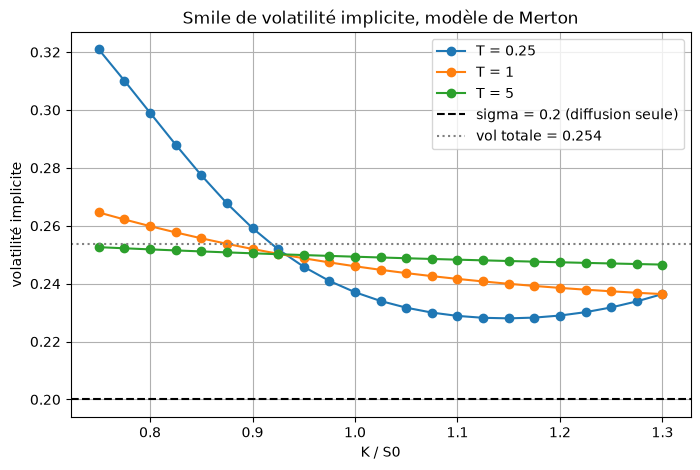

In [27]:
# Smile de volatilité implicite (prix calculés par COS)
from scipy.optimize import brentq

liste_T = [0.25, 1, 5]
liste_K = np.linspace(75, 130, 23)          # pas de 2.5, contient K = 100
sigma_tot = np.sqrt(sigma**2 + lam*(muJ**2 + delta**2))

plt.figure(figsize=(8, 5))
for Tm in liste_T:
    vol_impl = []
    for Kk in liste_K:
        prix = cos_call(S0, Kk, Tm, r, sigma, lam, muJ, delta, 128)
        vi = brentq(lambda s: bs_call(S0, Kk, Tm, r, s) - prix, 1e-4, 3)
        vol_impl.append(vi)
    print("T =", Tm, "  K=75 :", vol_impl[0], "  K=100 :", vol_impl[10], "  K=130 :", vol_impl[-1])
    plt.plot(liste_K/S0, vol_impl, 'o-', label="T = " + str(Tm))

plt.axhline(sigma, color='k', linestyle='--', label="sigma = 0.2 (diffusion seule)")
plt.axhline(sigma_tot, color='gray', linestyle=':', label="vol totale = " + str(round(sigma_tot, 3)))
plt.xlabel("K / S0")
plt.ylabel("volatilité implicite")
plt.title("Smile de volatilité implicite, modèle de Merton")
plt.legend()
plt.grid()
plt.show()

lambda = 0.25   K=75 : 0.27149516644298166   K=100 : 0.2124809818916506   K=130 : 0.21472022018738485
lambda = 0.75   K=75 : 0.3209111624782169   K=100 : 0.237046604180899   K=130 : 0.23640632239430687
lambda = 1.5   K=75 : 0.36676317700146305   K=100 : 0.2727053479362985   K=130 : 0.26231373034693795
muJ = -0.2   K=75 : 0.3810844727441886   K=100 : 0.26185607868199173   K=130 : 0.22700605371299787
muJ = -0.1   K=75 : 0.3209111624782169   K=100 : 0.237046604180899   K=130 : 0.23640632239430687
muJ = 0   K=75 : 0.27229122998621685   K=100 : 0.22938800710831758   K=130 : 0.27092614577360397
muJ = 0.1   K=75 : 0.2404351538527418   K=100 : 0.243497550465328   K=130 : 0.3269639308788066
delta = 0.05   K=75 : 0.25061397936700647   K=100 : 0.2190528485270585   K=130 : 0.20908924245744073
delta = 0.15   K=75 : 0.3209111624782169   K=100 : 0.237046604180899   K=130 : 0.23640632239430687
delta = 0.25   K=75 : 0.38720306885070765   K=100 : 0.2636976722742336   K=130 : 0.30761417973169086


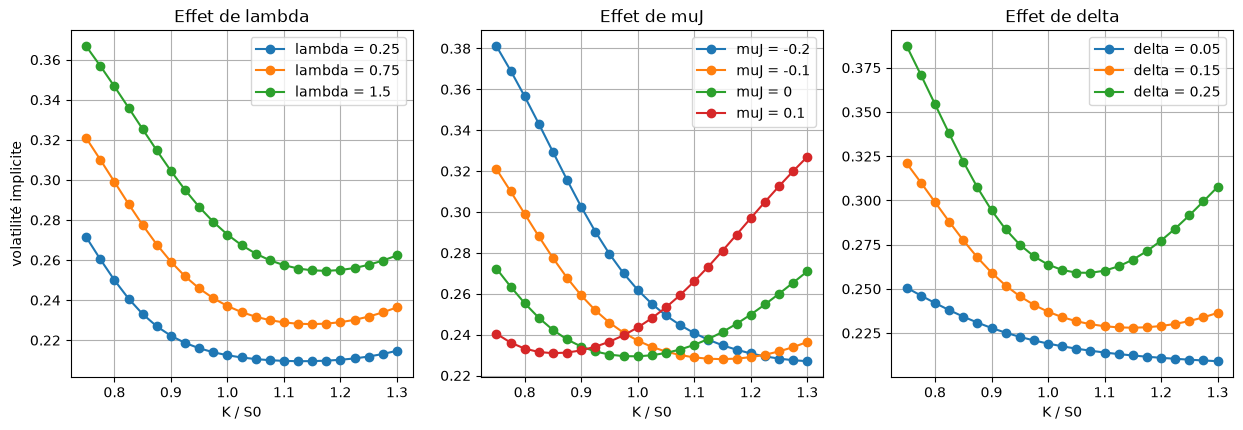

In [28]:
# Sensibilité du smile à lambda, muJ et delta (T = 0.25, un paramètre à la fois)
Tm = 0.25
liste_K = np.linspace(75, 130, 23)

plt.figure(figsize=(15, 4.5))

# 1) lambda
plt.subplot(1, 3, 1)
for l in [0.25, 0.75, 1.5]:
    vol_impl = []
    for Kk in liste_K:
        prix = cos_call(S0, Kk, Tm, r, sigma, l, muJ, delta, 128)
        vol_impl.append(brentq(lambda s: bs_call(S0, Kk, Tm, r, s) - prix, 1e-4, 3))
    print("lambda =", l, "  K=75 :", vol_impl[0], "  K=100 :", vol_impl[10], "  K=130 :", vol_impl[-1])
    plt.plot(liste_K/S0, vol_impl, 'o-', label="lambda = " + str(l))
plt.xlabel("K / S0"); plt.ylabel("volatilité implicite"); plt.title("Effet de lambda"); plt.legend(); plt.grid()

# 2) muJ
plt.subplot(1, 3, 2)
for m in [-0.2, -0.1, 0, 0.1]:
    vol_impl = []
    for Kk in liste_K:
        prix = cos_call(S0, Kk, Tm, r, sigma, lam, m, delta, 128)
        vol_impl.append(brentq(lambda s: bs_call(S0, Kk, Tm, r, s) - prix, 1e-4, 3))
    print("muJ =", m, "  K=75 :", vol_impl[0], "  K=100 :", vol_impl[10], "  K=130 :", vol_impl[-1])
    plt.plot(liste_K/S0, vol_impl, 'o-', label="muJ = " + str(m))
plt.xlabel("K / S0"); plt.title("Effet de muJ"); plt.legend(); plt.grid()

# 3) delta
plt.subplot(1, 3, 3)
for dl in [0.05, 0.15, 0.25]:
    vol_impl = []
    for Kk in liste_K:
        prix = cos_call(S0, Kk, Tm, r, sigma, lam, muJ, dl, 128)
        vol_impl.append(brentq(lambda s: bs_call(S0, Kk, Tm, r, s) - prix, 1e-4, 3))
    print("delta =", dl, "  K=75 :", vol_impl[0], "  K=100 :", vol_impl[10], "  K=130 :", vol_impl[-1])
    plt.plot(liste_K/S0, vol_impl, 'o-', label="delta = " + str(dl))
plt.xlabel("K / S0"); plt.title("Effet de delta"); plt.legend(); plt.grid()

plt.show()